# 02 桥长扫描（宽 8 m）与桥宽–桥长认证图

**8 m 宽是定死的吗？** 不是。8 m 是主实验那座桥的宽度，`bridge_case(cfg, length, width)` 的宽度是参数。
本 notebook 主扫描固定 8 m 宽（与主实验同一座桥型，只改桥长），第二部分另做桥宽 × 桥长的入口认证图，
说明结论如何随宽度变化。所有运行使用同一组误差界参数。

**第一部分：桥长扫描。** 30 个随机世界（入口状态、海流、种子，分布与 01 相同，全部在声明界内），
每个世界在每个桥长上都跑一遍（共同随机数），对比：
- “能过”比例：事后 oracle（无滤波 ILOS，入口切到 14 个候选航速之一，有一个航速无碰撞通过即算能过）；
- 滤波器放行率与撞墙率（本文方法，确定性误差盒）；
- ILOS 成功率（0.7 m/s 名义 ILOS，无入口判断，断星盲行）；
- EKF 3σ 放行率与撞墙率（同一安全滤波，只把误差盒换成 EKF 式协方差的 3σ，见 03）。

**第二部分：桥宽 × 桥长认证图。** 用主实验世界（`TruthSpec` 默认值，真实射流误差 +0.20 m/s，接近声明界 0.22），
对每个 (宽, 长) 只做入口认证（确定性误差盒、EKF 3σ）和事后 oracle，得到各宽度下的最长可认证桥长。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import sample_scenario, run_batch, pmap, gate_and_oracle, DEFAULT_SCENARIO
from bridge_sim.metrics import wilson, feasible

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
LENGTHS = [11, 15, 19, 23, 27, 31, 35, 40, 45, 50]
K_WORLDS = 30
METHODS = ('filter', 'ekf3s', 'ilos07', 'oracle')

def sweep_scenarios():
    rng = np.random.default_rng(2028)
    worlds = [sample_scenario(rng, 30000 + k) for k in range(K_WORLDS)]
    return [replace(w, length=float(L), width=8.0) for L in LENGTHS for w in worlds]

In [2]:
path = RES/'length_sweep.csv'
if path.exists():
    sweep = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    sweep = pd.DataFrame(run_batch(sweep_scenarios(), METHODS, workers=WORKERS, log_path=str(RES/'progress.log')))
    sweep.to_csv(path, index=False); print(f'{len(sweep)} runs in {time.time()-t0:.0f} s')
assert 'error' not in sweep or sweep['error'].isna().all()

loading length_sweep.csv


In [3]:
def frac(mask_by_L):
    k = mask_by_L.groupby(sweep['length']).sum(); n = mask_by_L.groupby(sweep['length']).size()
    lo, hi = zip(*[wilson(a, b) for a, b in zip(k, n)])
    return pd.DataFrame({'rate': k/n, 'lo': lo, 'hi': hi, 'k': k, 'n': n})

adm_f = sweep['filter_admitted'].fillna(False).astype(bool)
adm_e = sweep['ekf3s_admitted'].fillna(False).astype(bool)
curves = {
    'Feasible (hindsight ILOS, any speed)': frac(feasible(sweep, 'filter')),
    'Filter accept (proposed)':             frac(adm_f),
    'Filter collision':                     frac(sweep['filter_collided'].astype(bool)),
    'ILOS 0.7 m/s success':                 frac(sweep['ilos07_completed'] & ~sweep['ilos07_collided']),
    'ILOS 0.7 m/s collision':               frac(sweep['ilos07_collided'].astype(bool)),
    'EKF 3σ accept':                        frac(adm_e),
    'EKF 3σ collision':                     frac(sweep['ekf3s_collided'].astype(bool)),
}
summary = pd.concat({k: v for k, v in curves.items()}, names=['curve', 'length']).reset_index()
summary.to_csv(RES/'length_sweep_summary.csv', index=False)
summary.pivot(index='length', columns='curve', values='rate').round(3)

curve,EKF 3σ accept,EKF 3σ collision,"Feasible (hindsight ILOS, any speed)",Filter accept (proposed),Filter collision,ILOS 0.7 m/s collision,ILOS 0.7 m/s success
length,,,,,,,
11.0,1.0,0.0,1.000,1.000,0.0,0.000,1.000
15.0,1.0,0.0,1.000,1.000,0.0,0.000,1.000
19.0,1.0,0.0,1.000,1.000,0.0,0.067,0.933
23.0,1.0,0.0,1.000,0.067,0.0,0.067,0.933
27.0,1.0,0.0,1.000,0.000,0.0,0.233,0.767
31.0,1.0,0.0,1.000,0.000,0.0,0.333,0.667
35.0,1.0,0.0,1.000,0.000,0.0,0.433,0.567
40.0,0.0,0.0,0.967,0.000,0.0,0.433,0.567
45.0,0.0,0.0,0.967,0.000,0.0,0.533,0.467


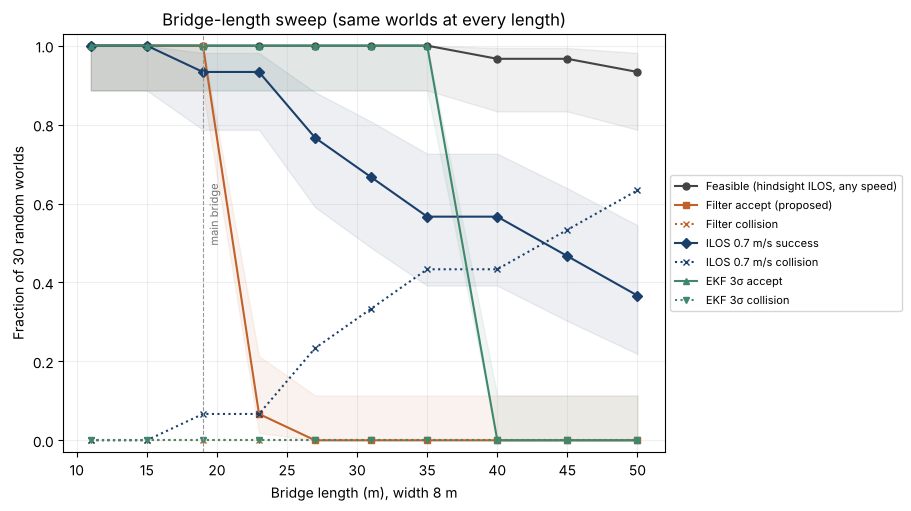

In [4]:
styles = {
    'Feasible (hindsight ILOS, any speed)': ('#444444', '-', 'o'),
    'Filter accept (proposed)':             ('#c0612b', '-', 's'),
    'Filter collision':                     ('#c0612b', ':', 'x'),
    'ILOS 0.7 m/s success':                 ('#1b3f6b', '-', 'D'),
    'ILOS 0.7 m/s collision':               ('#1b3f6b', ':', 'x'),
    'EKF 3σ accept':                        ('#40886c', '-', '^'),
    'EKF 3σ collision':                     ('#40886c', ':', 'v'),
}
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
for name, df in curves.items():
    col, ls, mk = styles[name]
    ax.plot(df.index, df['rate'], ls=ls, marker=mk, color=col, label=name, ms=5)
    if 'collision' not in name:
        ax.fill_between(df.index, df['lo'], df['hi'], color=col, alpha=.08)
ax.set(xlabel='Bridge length (m), width 8 m', ylabel=f'Fraction of {K_WORLDS} random worlds',
       title='Bridge-length sweep (same worlds at every length)', ylim=(-.03, 1.03))
ax.axvline(19, color='#999', lw=.8, ls='--'); ax.text(19.3, .5, 'main bridge', rotation=90, color='#777', fontsize=8)
ax.grid(alpha=.2); ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.0, .5))
fig.savefig(FIG/'length_sweep.png', dpi=200); fig.savefig(FIG/'length_sweep.pdf')
plt.show()

In [5]:
# Where the proposed filter is conservative: admitted-vs-feasible gap and collision counts
gap = pd.DataFrame({
    'feasible': feasible(sweep, 'filter').groupby(sweep['length']).sum(),
    'filter_admit': adm_f.groupby(sweep['length']).sum(),
    'filter_coll': sweep['filter_collided'].groupby(sweep['length']).sum(),
    'filter_certloss': sweep['filter_cert_lost'].groupby(sweep['length']).sum(),
    'ekf_admit': adm_e.groupby(sweep['length']).sum(),
    'ekf_coll': sweep['ekf3s_collided'].groupby(sweep['length']).sum(),
    'ekf_admit_infeasible': (adm_e & ~feasible(sweep, 'ekf3s')).groupby(sweep['length']).sum(),
    'ilos_coll': sweep['ilos07_collided'].groupby(sweep['length']).sum(),
    'filter_cov_E_max': sweep['filter_cov_ratio_E'].groupby(sweep['length']).max(),
    'ekf_cov_E_max': sweep['ekf3s_cov_ratio_E'].groupby(sweep['length']).max(),
})
gap

,feasible,filter_admit,filter_coll,filter_certloss,ekf_admit,ekf_coll,ekf_admit_infeasible,ilos_coll,filter_cov_E_max,ekf_cov_E_max
length,,,,,,,,,,
11.0,30,30,0,0,30,0,0,0,0.984442,1.3139
15.0,30,30,0,0,30,0,0,0,0.984442,1.3139
19.0,30,30,0,0,30,0,0,2,0.984442,1.3139
23.0,30,2,0,0,30,0,0,2,0.984442,1.3139
27.0,30,0,0,0,30,0,0,7,0.984442,1.3991
31.0,30,0,0,0,30,0,0,10,0.984442,1.3139
35.0,30,0,0,0,30,0,0,13,0.984442,1.3139
40.0,29,0,0,0,0,0,0,13,0.984442,1.3139
45.0,29,0,0,0,0,0,0,16,0.984442,1.3139


## 第二部分：桥宽 × 桥长入口认证图（主实验世界）

In [6]:
WIDTHS = [5, 6, 7, 8, 10, 12]
MAP_LENGTHS = list(range(9, 61, 3))
path = RES/'width_length_map.csv'
if path.exists():
    wl = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    jobs = [dict(s=replace(DEFAULT_SCENARIO, length=float(L), width=float(W))) for W in WIDTHS for L in MAP_LENGTHS]
    wl = pd.DataFrame(pmap(gate_and_oracle, jobs, workers=WORKERS))
    wl.to_csv(path, index=False); print(f'{len(wl)} cells in {time.time()-t0:.0f} s')
assert 'error' not in wl or wl['error'].isna().all()

def longest(df, col):
    ok = df[df[col].astype(bool)]
    return ok['length'].max() if len(ok) else np.nan

lim = pd.DataFrame({
    'box (proposed)': wl.groupby('width').apply(lambda d: longest(d, 'box_admitted')),
    'EKF 3σ': wl.groupby('width').apply(lambda d: longest(d, 'ekf_admitted')),
    'hindsight feasible': wl.groupby('width').apply(lambda d: longest(d, 'oracle_feasible')),
})
lim.to_csv(RES/'width_length_limits.csv')
lim

loading width_length_map.csv


,box (proposed),EKF 3σ,hindsight feasible
width,,,
5.0,9.0,15.0,18.0
6.0,12.0,21.0,24.0
7.0,15.0,27.0,33.0
8.0,21.0,36.0,39.0
10.0,27.0,48.0,54.0
12.0,36.0,60.0,60.0


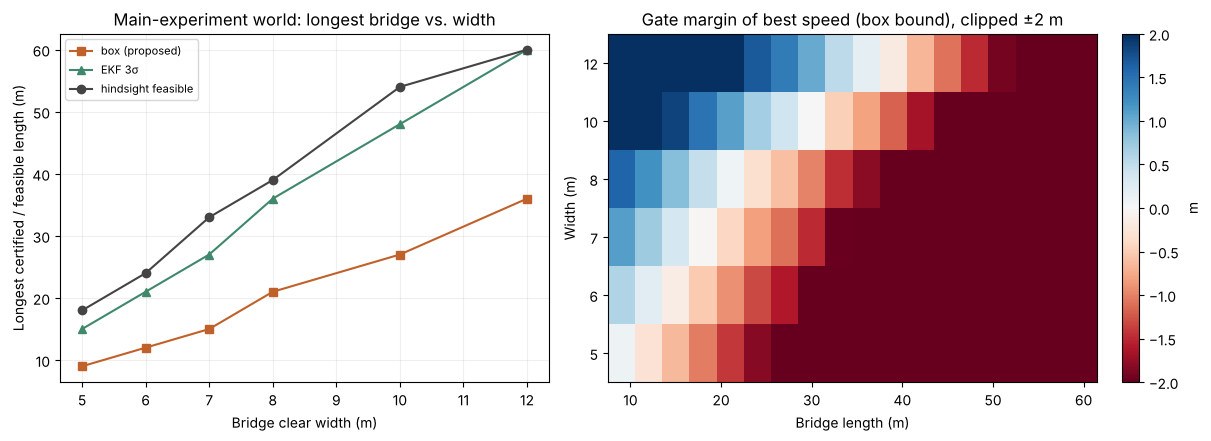

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
ax = axes[0]
for col, (c, mk) in zip(lim.columns, (('#c0612b', 's'), ('#40886c', '^'), ('#444444', 'o'))):
    ax.plot(lim.index, lim[col], marker=mk, color=c, label=col)
ax.set(xlabel='Bridge clear width (m)', ylabel='Longest certified / feasible length (m)',
       title='Main-experiment world: longest bridge vs. width')
ax.grid(alpha=.2); ax.legend(fontsize=8)
ax = axes[1]
piv = wl.pivot(index='width', columns='length', values='box_entry_margin').replace(-np.inf, np.nan)
im = ax.imshow(np.clip(piv.values, -2, 2), aspect='auto', origin='lower', cmap='RdBu',
               extent=[MAP_LENGTHS[0]-1.5, MAP_LENGTHS[-1]+1.5, -.5, len(WIDTHS)-.5], vmin=-2, vmax=2)
ax.set_yticks(range(len(WIDTHS)), [str(w) for w in WIDTHS])
ax.set(xlabel='Bridge length (m)', ylabel='Width (m)', title='Gate margin of best speed (box bound), clipped ±2 m')
fig.colorbar(im, ax=ax, label='m')
fig.savefig(FIG/'width_length_map.png', dpi=200); fig.savefig(FIG/'width_length_map.pdf')
plt.show()

## 第三部分：最坏世界下的“能过”（保证的固有代价）

事后 oracle 知道这一次世界的真实海流，任何因果方法都做不到。要把“方法自身的保守”和“要求最坏情况保证的固有代价”分开，
需要看声明误差集合里的最坏世界：射流幅值误差取 ±0.22（声明界），背景流偏置、陀螺零偏、桥墙配准误差都取到界上，
四种符号组合。只要四个世界中有一个 ILOS 在所有候选航速下都过不去，这座桥就不存在“对所有允许世界都安全”的固定航速通行方案，
滤波器拒绝它是应该的。

In [8]:
def worst_worlds(L):
    out = []
    for sj in (1, -1):
        for so in (1, -1):
            out.append(replace(DEFAULT_SCENARIO, length=float(L), width=8.0, jet_amplitude_error=0.22*sj,
                               current_north_bias=0.010*so, current_east_bias=0.011*so, tide_amplitude=0.004,
                               gyro_bias=0.00055*so, wall_shift=-0.08*sj, initial_cross_track=0.5*so))
    return out
WC_LENGTHS = list(range(9, 52, 3))
path = RES/'worst_world_oracle.csv'
if path.exists():
    wc = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    scen = [s for L in WC_LENGTHS for s in worst_worlds(L)]
    wc = pd.DataFrame(pmap(gate_and_oracle, [dict(s=s) for s in scen], workers=WORKERS))
    wc['world'] = [f"jet{s.jet_amplitude_error:+.2f}/other{np.sign(s.current_east_bias):+.0f}" for s in scen]
    wc.to_csv(path, index=False); print(f'{len(wc)} cells in {time.time()-t0:.0f} s')
assert 'error' not in wc or wc['error'].isna().all()
wc_tab = wc.pivot(index='length', columns='world', values='oracle_best_clearance').round(2)
wc_tab['all four feasible'] = (wc.groupby('length')['oracle_feasible'].all())
wc_tab['box admitted (all four)'] = wc.groupby('length')['box_admitted'].all()
wc_tab['EKF admitted (all four)'] = wc.groupby('length')['ekf_admitted'].all()
wc_tab

loading worst_world_oracle.csv


world,jet+0.22/other+1,jet+0.22/other-1,jet-0.22/other+1,jet-0.22/other-1,all four feasible,box admitted (all four),EKF admitted (all four)
length,,,,,,,
9.0,1.74,1.84,2.76,2.85,True,True,True
12.0,1.77,1.87,2.73,2.82,True,True,True
15.0,1.61,1.70,2.14,1.92,True,True,True
18.0,1.37,1.54,1.94,1.86,True,True,True
21.0,1.12,1.25,1.64,1.60,True,True,True
24.0,0.91,1.13,1.41,1.14,True,False,True
27.0,0.55,0.60,1.14,1.05,True,False,True
30.0,0.35,0.49,0.93,0.80,True,False,True
33.0,0.24,0.17,0.58,0.52,True,False,True


### 最坏世界中的闭环运行（EKF 3σ 与本文方法）

上表只看入口决策和事后 oracle。下面把 EKF 3σ 安全滤波和本文方法在四个最坏世界里真正闭环跑一遍，看放行后是否撞墙、最小间隙多少。

In [9]:
from bridge_sim.ext import run_batch
WC_CL_LENGTHS = [15, 18, 21, 24, 27, 30, 33]
path = RES/'worst_world_closed_loop.csv'
if path.exists():
    wcl = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    scen = [s for L in WC_CL_LENGTHS for s in worst_worlds(L)]
    wcl = pd.DataFrame(run_batch(scen, ('filter', 'ekf3s'), workers=WORKERS, progress_every=0))
    wcl['world'] = [f"jet{s.jet_amplitude_error:+.2f}/other{np.sign(s.current_east_bias):+.0f}" for s in scen]
    wcl.to_csv(path, index=False); print(f'{len(wcl)} runs in {time.time()-t0:.0f} s')
assert 'error' not in wcl or wcl['error'].isna().all()
cols = ['length', 'world', 'filter_admitted', 'filter_transit_speed', 'filter_min_clearance', 'filter_collided',
        'ekf3s_admitted', 'ekf3s_transit_speed', 'ekf3s_min_clearance', 'ekf3s_collided', 'ekf3s_cert_lost',
        'filter_cov_ratio_E_blind', 'ekf3s_cov_ratio_E_blind']
wcl[cols].round(3)

loading worst_world_closed_loop.csv


,length,world,filter_admitted,filter_transit_speed,filter_min_clearance,filter_collided,ekf3s_admitted,ekf3s_transit_speed,ekf3s_min_clearance,ekf3s_collided,ekf3s_cert_lost,filter_cov_ratio_E_blind,ekf3s_cov_ratio_E_blind
0,15.0,jet+0.22/other+1,True,1.7,1.281,False,True,1.7,1.281,False,False,0.791,1.296
1,15.0,jet+0.22/other-1,True,1.7,1.511,False,True,1.7,1.511,False,False,0.697,1.047
2,15.0,jet-0.22/other+1,True,1.7,1.335,False,True,1.7,0.968,False,False,0.620,0.870
3,15.0,jet-0.22/other-1,True,1.7,1.195,False,True,1.7,0.826,False,False,0.718,1.084
4,18.0,jet+0.22/other+1,True,1.8,1.018,False,True,1.8,0.999,False,False,0.758,1.102
5,18.0,jet+0.22/other-1,True,1.8,1.114,False,True,1.8,1.277,False,False,0.703,1.046
6,18.0,jet-0.22/other+1,True,1.8,2.208,False,True,1.8,0.602,False,False,0.650,0.916
7,18.0,jet-0.22/other-1,True,1.8,1.973,False,True,1.8,0.532,False,False,0.711,1.006
8,21.0,jet+0.22/other+1,True,1.7,1.039,False,True,1.9,0.804,False,False,0.763,1.093
9,21.0,jet+0.22/other-1,True,1.7,1.123,False,True,1.9,0.771,False,False,0.706,1.088


## 结论

数字取自上面的实际运行（统一参数）。
**桥长扫描（8 m 宽，30 个世界 × 10 个桥长）**
- 本文方法：11–19 m 全部放行，23 m 放行 2/30，27 m 起全部拒绝；300 次运行撞墙 0，认证丢失 0。
- 0.7 m/s ILOS：撞墙率随桥长上升，19 m 为 2/30，31 m 为 10/30，50 m 为 19/30。这是“需要入口判断”的直接证据。
- 事后能过比例：35 m 以内 30/30，50 m 仍有 28/30。
- EKF 3σ：35 m 以内全部放行，40 m 起拒绝；随机世界里撞墙 0。但每个世界的 3σ 管都被突破，全程最大 1.40 倍。

**桥宽 × 桥长（主实验世界，最长可认证或可通过桥长）**

| 宽度 | 5 m | 6 m | 7 m | 8 m | 10 m | 12 m |
|---|---|---|---|---|---|---|
| 本文方法 | 9 | 12 | 15 | 21 | 27 | 36 |
| EKF 3σ | 15 | 21 | 27 | 36 | 48 | 60 |
| 事后能过 | 18 | 24 | 33 | 39 | 54 | 60 |

8 m 不是定死的，结论随宽度近似线性缩放。

**最坏世界（声明界上的四个世界）**
- 四个世界都能过的最长桥长是 33 m，36 m 起至少一个世界撞墙。本文方法认证到 21 m，EKF 3σ 放行到 36 m，36 m 已有不可通过的世界。
- 21 → 33 m 的差距是方法本身的保守（误差界在最坏世界只用到 0.62–0.79），见 04 的逐项分解。
- 最坏世界闭环（四个世界）：本文方法在 15–21 m 放行，最小间隙 1.02 m；EKF 3σ 在 15–33 m 全部放行，没有撞墙，但 33 m 时最小间隙只有 0.026 m。
- EKF 在 35–36 m 的撞墙见 04（8 个最坏世界）。